In [7]:
%pip install scikit-learn pandas numpy matplotlib scipy tensorflow



[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from scipy.stats import norm
from scipy.stats import wasserstein_distance
from pathlib import Path
data_dir = Path("/Users/angelaliu/Library/CloudStorage/OneDrive-MassachusettsInstituteofTechnology/Fracture Flow UROP/urop-angelaliu-fracflow - Copy/3-parameter data")


In [9]:
def fit_gmm_logq_for_theta(theta_key, df_all, theta_cols, q_col="Q",
                           max_components=8, criterion="bic",
                           random_state=0, n_init=10, allow_more_plots=False):
    """
    For one theta_key:
      - compute empirical p0 = P(Q=0)
      - fit GMM to logQ for Q>0
    Returns a dict mirroring the MDN parameter names: p0_emp, w, mu, sigma (on logQ).
    """
    sub = df_all[df_all["theta_key"] == theta_key]
    if len(sub) == 0:
        raise ValueError(f"theta_key not found: {theta_key}")

    q = sub[q_col].to_numpy(dtype=float)
    q = q[np.isfinite(q)]

    p0_emp = float(np.mean(q <= 0.0))
    q_pos = q[q > 0.0]

    theta = sub[theta_cols].iloc[0].to_numpy() # Moved this line up to ensure theta is always available

    if len(q_pos) < 2:  # You need at least 2 points to fit a 1-component GMM variance
        return {
          "theta_key": theta_key,
          "theta": theta, # Now returns the actual theta array
          "p0_emp": p0_emp,
          "q_pos": np.array([]),
          "logq": np.array([]),
          "K": 0,         # 0-component model
          "w": np.array([]),
          "mu": np.array([]),
          "sigma": np.array([]),
          "var": np.array([]),
          "criterion": criterion.lower(),
          "score": np.nan,
          "model": None,
          "logwd": np.nan,
      }

    logq = np.log(q_pos).reshape(-1, 1)

    best, best_score = None, np.inf
    K = 2 # number of components
    # for K in range(1, min(len(q_pos), max_components) + 1):
    gmm = GaussianMixture(
        n_components=K,
        covariance_type="full",   # in 1D this is fine
        random_state=random_state,
        n_init=n_init,
    ).fit(logq)

    score = gmm.bic(logq) if criterion.lower() == "bic" else gmm.aic(logq)
    if score < best_score:
        best, best_score = gmm, score

    w = best.weights_.copy()
    mu = best.means_.reshape(-1).copy()
    var = np.array(best.covariances_).reshape(-1).copy()
    sigma = np.sqrt(var)

    # Sort by mu for nicer reporting/plots
    order = np.argsort(mu)
    w, mu, sigma, var = w[order], mu[order], sigma[order], var[order]

    # Calculate Wasserstein distance
    # Draw samples from the fitted GMM in log-Q space
    gmm_samples_logq, _ = best.sample(len(logq))
    # Transform samples back to Q-space
    gmm_samples_q_pos = np.exp(gmm_samples_logq).flatten()
    # Compute Wasserstein distance between real Q-pos samples and GMM Q-pos samples
    logwd = np.log(wasserstein_distance(gmm_samples_q_pos, q_pos))

    logq_range = np.linspace(min(logq)-0.5, max(logq)+0.5)
    pdf = sum (w * norm.pdf(logq_range, loc=mu, scale=sigma) for w, mu, sigma in zip(w, mu, sigma))
    plt.plot(logq_range, pdf)
    plt.hist(logq, bins=30, density=True, alpha=0.6, color='gray', label='Empirical log(Q) Histogram')
    if not allow_more_plots:
      plt.show()

    return {
        "theta_key": theta_key,
        "theta": theta,
        "p0_emp": p0_emp,
        "q_pos": q_pos,
        "logq": logq.reshape(-1),
        "K": int(best.n_components),
        "w": w,
        "mu": mu,
        "sigma": sigma,
        "var": var,
        "criterion": criterion.lower(),
        "score": float(best_score),
        "model": best,
        "logwd": float(logwd),
        "logq_range": logq_range,
        "pdf": pdf
    }

In [6]:

all_file_indices = []
valid_file_indices = []
outputs_raw = {} # valid file index: clean 7-tuple
all_thetas = {} # file index : clean theta-tuple
high_p0_thetas = {} # file index: clean theta-tuple with p0
for ind in range(1, 10001): # 1899
    try:
        df = pd.read_csv(data_dir / f"flow_outputs_{ind}.csv")

        theta_cols = ['discspacing','length_ratio','b']
        df["theta_key"] = (
            df[theta_cols]
            .round(5)
            .astype(str)
            .agg("_".join, axis=1)
        )

        theta_key = df["theta_key"].iloc[0]

        fit = fit_gmm_logq_for_theta(theta_key, df, theta_cols, q_col="Q",
                                     max_components=8, criterion="bic", allow_more_plots=False)

        # Clean the values (Native python types, rounded to 2 decimals)
        clean_theta = tuple(round(float(val), 5) for val in fit["theta"])
        p0_clean = round(float(fit["p0_emp"]), 5)
        w_clean = tuple(np.round(fit["w"], 2).tolist())
        mu_clean = tuple(np.round(fit["mu"], 5).tolist())
        sigma_clean = tuple(np.round(fit["sigma"], 5).tolist())
        logwd_clean = round(float(fit["logwd"]), 5)

        all_file_indices.append(ind)
        if fit['K'] == 2:
            valid_file_indices.append(ind)
            outputs_raw[ind] = (p0_clean, w_clean, mu_clean, sigma_clean, logwd_clean)

        all_thetas[ind] = clean_theta
        if p0_clean > 0.9:
            high_p0_thetas[ind] = (*clean_theta, p0_clean)
    except Exception:
        continue


In [9]:
import pickle
outputs_dir = data_dir.parent.parent / "outputs"
with open(outputs_dir / 'notebook_state (before additional trials).pkl', 'rb') as f:
    state = pickle.load(f)
all_thetas        = state['all_thetas']
all_file_indices  = state['all_file_indices']
valid_file_indices= state['valid_file_indices']
outputs_raw       = state['outputs_raw']
high_p0_thetas    = state['high_p0_thetas']
thetas_means      = state['thetas_means']
thetas_stds       = state['thetas_stds']
outputs_means     = state['outputs_means']
outputs_stds      = state['outputs_stds']
print('loaded')

loaded


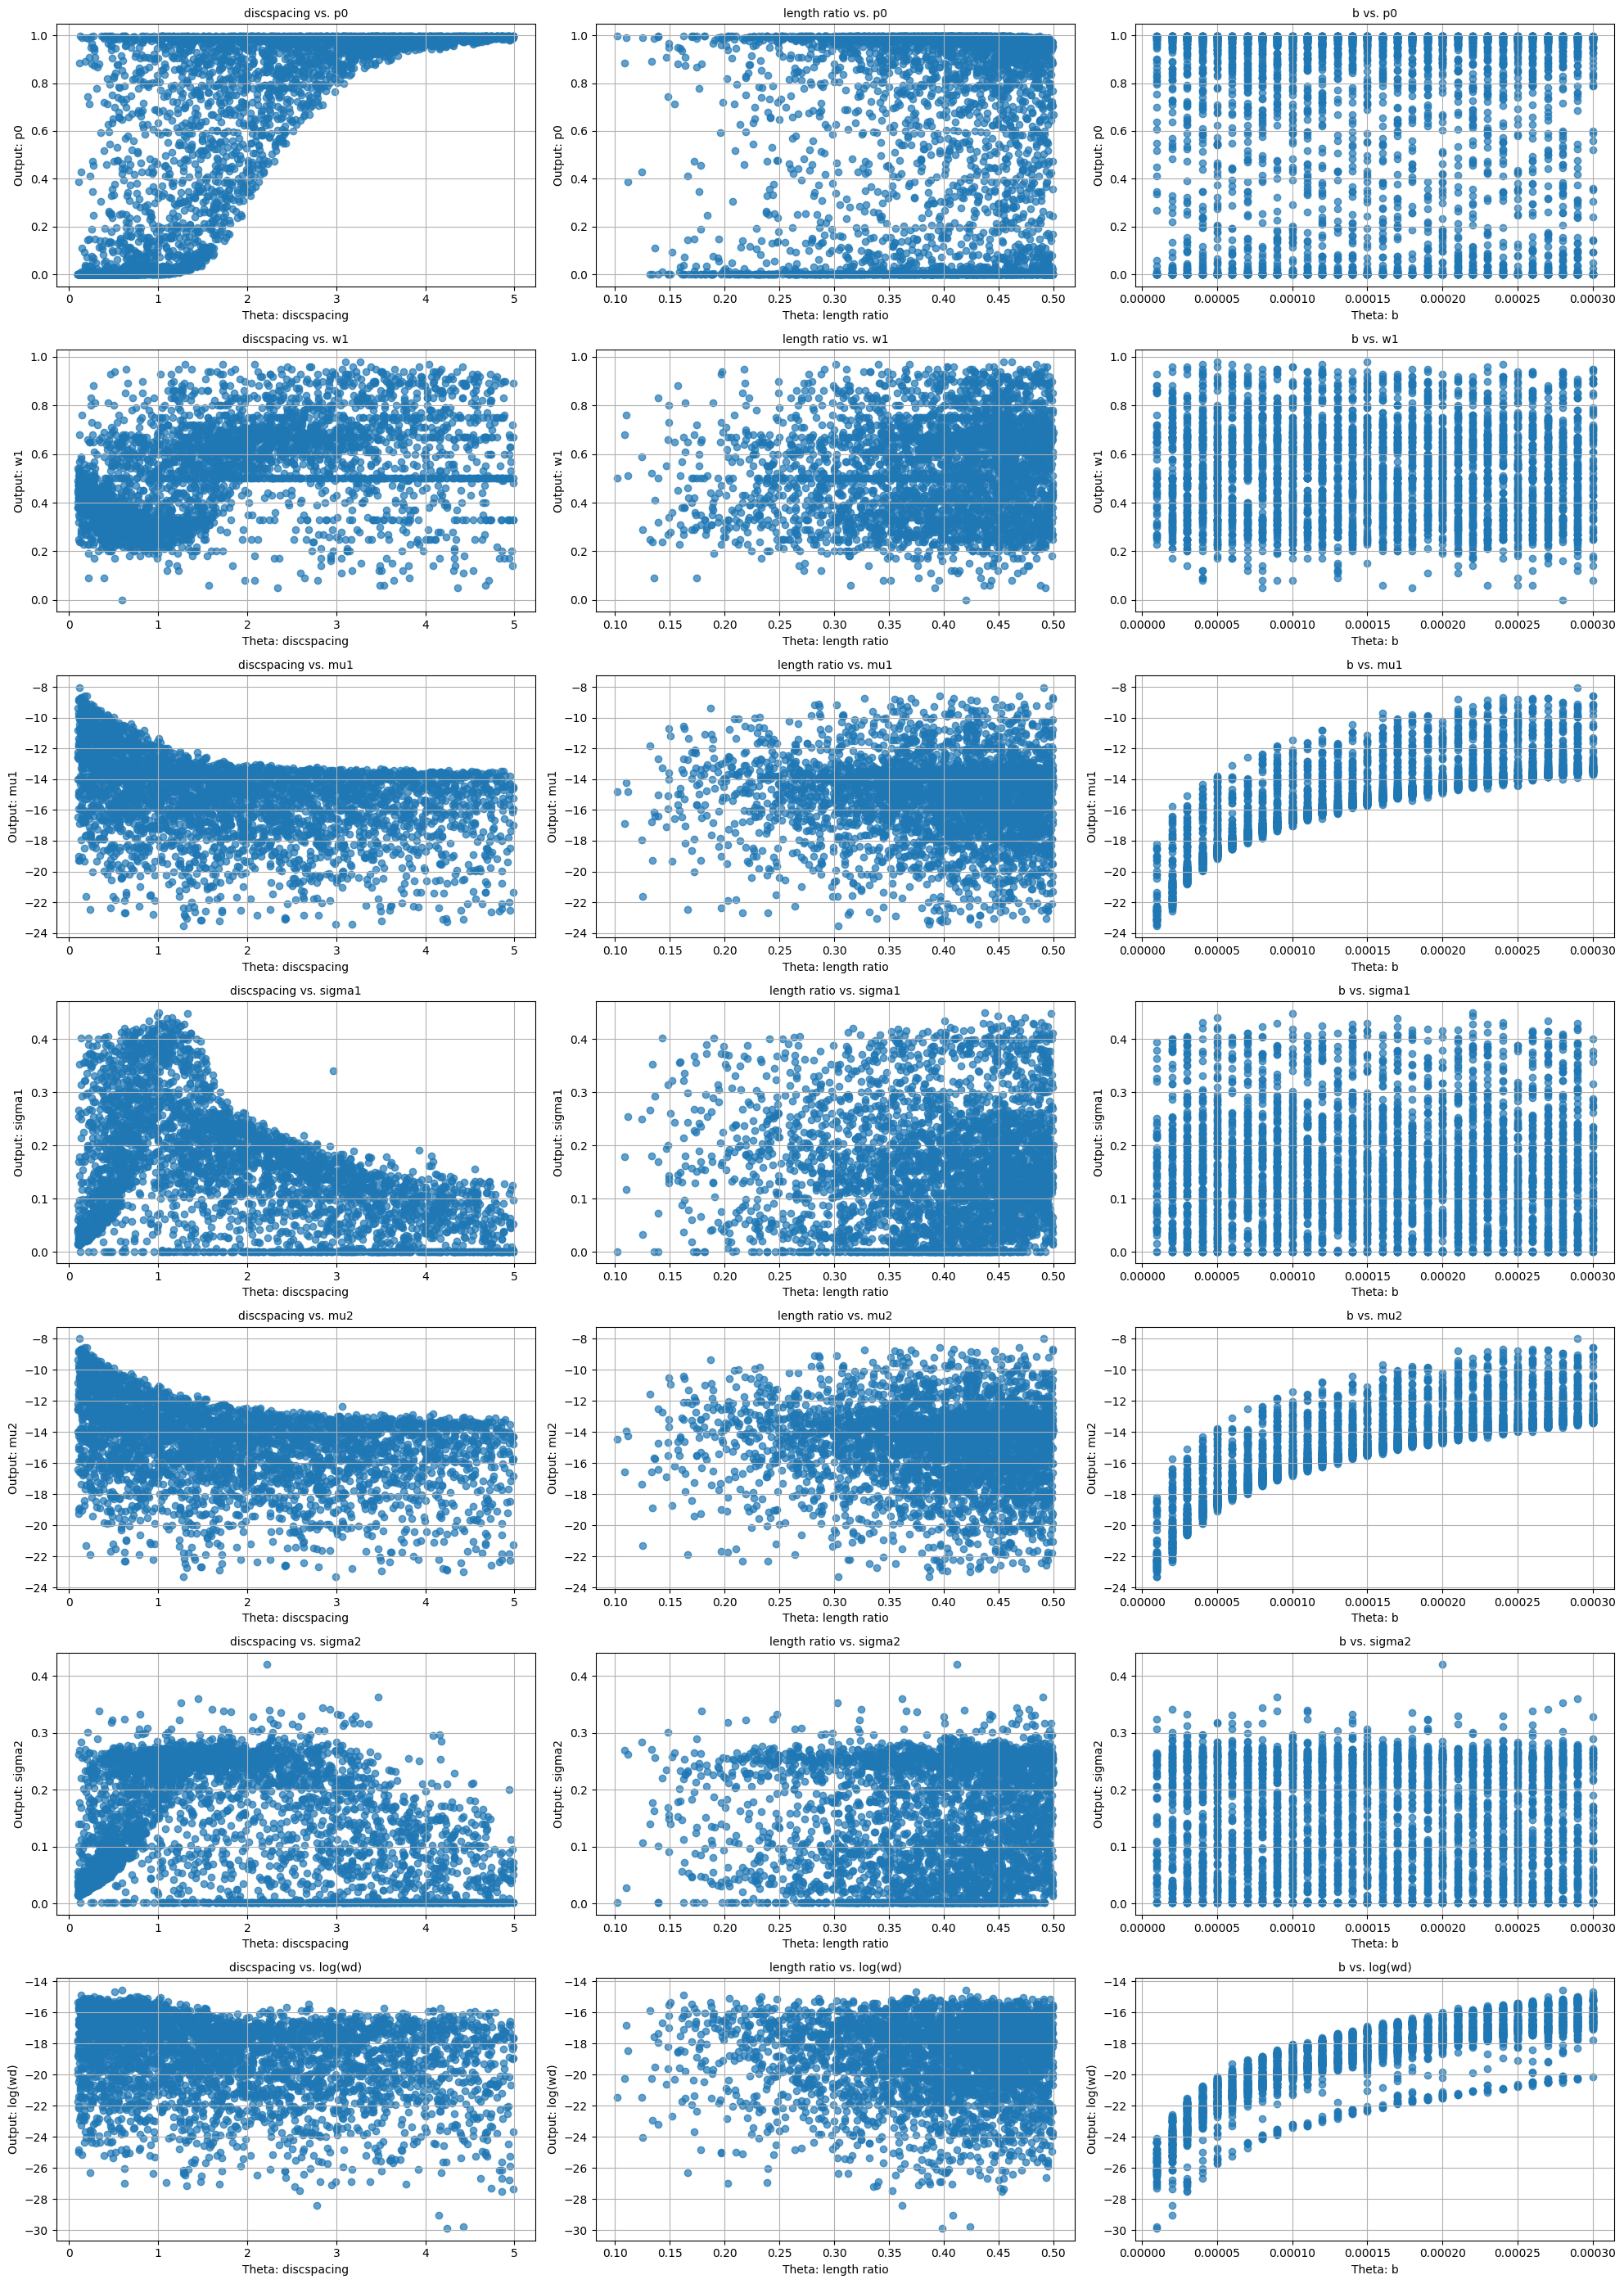

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# Process outputs_raw to create a homogeneous all_outputs array
all_thetas_processed = [] # list version of the dict
all_outputs_processed = [] # list version of the dict
for ind in valid_file_indices: # all_file_indices; ‘valid file’ means a fit can be made; a ‘good file’ means p0 < 0.99. You always do train with valid files only, but the scatter plots used to be done with all files.
    p0_val, w_vals, mu_vals, sigma_vals, logwd_val = outputs_raw[ind]

    current_row = [p0_val]

    if len(w_vals) == 2: # K=2 components
        current_row.append(w_vals[0])
        current_row.append(mu_vals[0])
        current_row.append(sigma_vals[0])
        current_row.append(mu_vals[1])
        current_row.append(sigma_vals[1])
        current_row.append(logwd_val)
    elif len(w_vals) == 0: # K=0 components
        current_row.extend([np.nan, np.nan, np.nan, np.nan, np.nan, np.nan]) # Pad for w1, mu1, sigma1, mu2, sigma2, and wd

    all_thetas_processed.append(list(all_thetas[ind]))
    all_outputs_processed.append(current_row)

all_thetas_processed = np.array(all_thetas_processed)
all_outputs_processed = np.array(all_outputs_processed, dtype=float)

theta_param_names = ["discspacing", "length ratio", "b"]
output_param_names = ["p0", "w1", "mu1", "sigma1", "mu2", "sigma2", "log(wd)"]

# Create a single figure with 7 rows and 3 columns
fig, axes = plt.subplots(nrows=7, ncols=3, figsize=(20, 28))

for j in range(7): # Iterate through output parameters (rows)
    for i in range(3): # Iterate through theta parameters (columns)
        ax = axes[j, i]

        # Filter out NaN values from outputs for plotting
        # np.isfinite works for float, so if `all_outputs` contains np.nan, this is correct
        valid_indices = np.where(np.isfinite(all_outputs_processed[:, j])) # this is specific to j

        # Convert filtered data to float and plot
        ax.scatter(all_thetas_processed[valid_indices, i].astype(float), all_outputs_processed[valid_indices, j], alpha=0.7)
        ax.set_xlabel(f"Theta: {theta_param_names[i]}")
        ax.set_ylabel(f"Output: {output_param_names[j]}")
        ax.set_title(f"{theta_param_names[i]} vs. {output_param_names[j]}", fontsize=10)
        ax.grid(True)

plt.tight_layout()
plt.show()

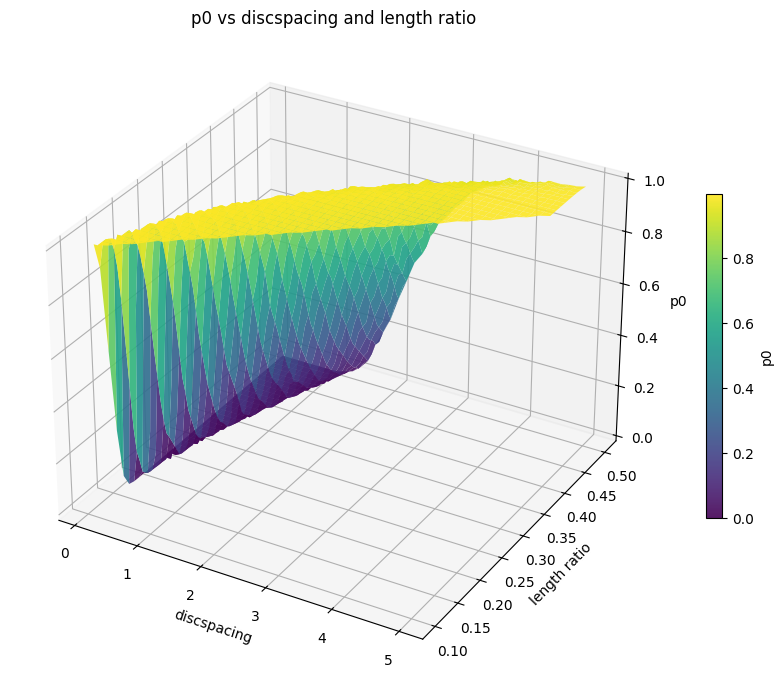

In [12]:
from mpl_toolkits.mplot3d import Axes3D
from scipy.interpolate import griddata

disc = all_thetas_processed[:, 0]
lr   = all_thetas_processed[:, 1]
p0   = all_outputs_processed[:, 0]

valid = np.isfinite(p0)
disc_v, lr_v, p0_v = disc[valid], lr[valid], p0[valid]

disc_grid = np.linspace(disc_v.min(), disc_v.max(), 80)
lr_grid   = np.linspace(lr_v.min(),   lr_v.max(),   80)
DD, LL    = np.meshgrid(disc_grid, lr_grid)
P0_surf   = griddata((disc_v, lr_v), p0_v, (DD, LL), method='linear')

fig = plt.figure(figsize=(10, 7))
ax  = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(DD, LL, P0_surf, cmap='viridis', alpha=0.9)
fig.colorbar(surf, ax=ax, shrink=0.5, label='p0')
ax.set_xlabel('discspacing')
ax.set_ylabel('length ratio')
ax.set_zlabel('p0')
ax.set_title('p0 vs discspacing and length ratio')
plt.tight_layout()
plt.show()

In [9]:
# Visualizing one output parameter at a time.
# discspacing_values = all_thetas[:, 0].astype(float) # discspacing is the 0th theta parameter
# lx_values = all_thetas[:, 1].astype(float)          # lx is the 1st theta parameter
# aperture_values = all_thetas[:, 2].astype(float)    # 'b' (aperture) is the 2nd theta parameter
# p0_values = all_outputs[:, 0].astype(float)         # p0 is the 0th output parameter

# # Filter out entries where p0 might be None/NaN
# valid_indices = np.where(np.isfinite(p0_values))

# discspacing_values = discspacing_values[valid_indices]
# lx_values = lx_values[valid_indices]
# aperture_values = aperture_values[valid_indices]
# p0_values = p0_values[valid_indices]

# # Create the 3D scatter plot
# fig = plt.figure(figsize=(10, 8))
# ax = fig.add_subplot(111, projection='3d')

# scatter = ax.scatter(
#     discspacing_values,
#     lx_values,
#     aperture_values,
#     c=p0_values,          # Color by p0 value
#     cmap='viridis',       # Choose a colormap
#     s=50,                 # Marker size
#     alpha=0.8
# )

# # Add labels and title
# ax.set_xlabel('discspacing')
# ax.set_ylabel('length ratio')
# ax.set_zlabel('aperture (b)')
# ax.set_title('3D Scatter Plot: (discspacing, length ratio, aperture) colored by p0')

# # Add a color bar for p0 values
# cbar = fig.colorbar(scatter, ax=ax, pad=0.1)
# cbar.set_label('p0 value')

# plt.tight_layout()
# plt.show()

In [37]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

valid_indices = np.where(all_outputs_processed[:, 1].astype(float) >= 0)
thetas = all_thetas_processed[valid_indices] # numpy arrays of thetas of files with a fit
outputs = all_outputs_processed[valid_indices] # numpy arrays of outputs of files with a fit

thetas_means = np.mean(thetas, axis=0)
thetas_stds = np.std(thetas, axis=0)
thetas_norm = (thetas - thetas_means) / thetas_stds
outputs_means = np.mean(outputs, axis=0)
outputs_stds = np.std(outputs, axis=0)
outputs_norm = (outputs - outputs_means) / outputs_stds

In [ ]:
from sklearn.model_selection import train_test_split
thetas_train, thetas_val, outputs_train, outputs_val = train_test_split(thetas_norm, outputs_norm, test_size=0.2, random_state=42)
models = []
for training_num in range(1,2): # number of model attempts
    l2_reg = 9e-5
    model = keras.Sequential([
        layers.Input(shape=(3,)),
        layers.Dense(20, activation="relu",
                    kernel_regularizer=regularizers.l2(l2_reg)),
        layers.Dense(20, activation="relu",
                    kernel_regularizer=regularizers.l2(l2_reg)),
        layers.Dense(20, activation="relu",
                    kernel_regularizer=regularizers.l2(l2_reg)),
        layers.Dense(20, activation="relu",
                    kernel_regularizer=regularizers.l2(l2_reg)),
        layers.Dense(7)
    ])

    def lr_by_epoch(epoch):
        if epoch < 500:   return 1e-3
        elif epoch < 750: return 5e-4
        else:             return 1e-4

    lr_callback = keras.callbacks.LearningRateScheduler(lr_by_epoch, verbose=0)

    class PrintEvery(keras.callbacks.Callback):
        def on_epoch_end(self, epoch, logs=None):
            if (epoch + 1) % 100 == 0:
                print(f"Epoch {epoch+1} \u2014 loss: {logs['loss']:.4f}, val_loss: {logs['val_loss']:.4f}")
    print_callback = PrintEvery()

    # weights: [p0, w1, mu1, sigma1, mu2, sigma2, log_wd]
    loss_weights = tf.constant([1.0, 2.0, 3.0, 2.0, 3.0, 2.0, 0.5], dtype=tf.float32)
    loss_weights = loss_weights / tf.reduce_sum(loss_weights)  # normalize to sum to 1
    def weighted_mse(y_true, y_pred):
        return tf.reduce_mean(tf.reduce_sum(loss_weights * tf.square(y_true - y_pred), axis=1))

    # --- Wasserstein-1 loss (commented out: gives poor sigma gradient for narrow peaks) ---
    # _x_grid = tf.cast(tf.linspace(-82.0, -32.0, 4000), tf.float32)
    # _dx = _x_grid[1] - _x_grid[0]
    # _out_means = tf.constant(outputs_means, dtype=tf.float32)
    # _out_stds  = tf.constant(outputs_stds,  dtype=tf.float32)
    # def _normal_cdf(x, mu, sigma):
    #     return 0.5 * (1.0 + tf.math.erf((x - mu) / (sigma * tf.sqrt(2.0))))
    # def wasserstein_gmm_loss(y_true, y_pred):
    #     t = y_true * _out_stds + _out_means
    #     p = y_pred * _out_stds + _out_means
    #     p0_loss = tf.reduce_mean(tf.square(t[:, 0] - p[:, 0]))
    #     w1_t = tf.reshape(t[:, 1], (-1, 1))
    #     m1_t = tf.reshape(t[:, 2], (-1, 1));  s1_t = tf.reshape(tf.abs(t[:, 3]), (-1, 1))
    #     m2_t = tf.reshape(t[:, 4], (-1, 1));  s2_t = tf.reshape(tf.abs(t[:, 5]), (-1, 1))
    #     w1_p = tf.reshape(p[:, 1], (-1, 1))
    #     m1_p = tf.reshape(p[:, 2], (-1, 1));  s1_p = tf.reshape(tf.abs(p[:, 3]), (-1, 1))
    #     m2_p = tf.reshape(p[:, 4], (-1, 1));  s2_p = tf.reshape(tf.abs(p[:, 5]), (-1, 1))
    #     x = tf.reshape(_x_grid, (1, -1))
    #     cdf_t = w1_t * _normal_cdf(x, m1_t, s1_t) + (1 - w1_t) * _normal_cdf(x, m2_t, s2_t)
    #     cdf_p = w1_p * _normal_cdf(x, m1_p, s1_p) + (1 - w1_p) * _normal_cdf(x, m2_p, s2_p)
    #     wd_loss = tf.reduce_mean(tf.reduce_sum(tf.abs(cdf_t - cdf_p), axis=1) * _dx)
    #     return wd_loss + p0_loss

    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss=weighted_mse
    )

    # training
    history = model.fit(
        thetas_norm, outputs_norm,
        batch_size=32,
        epochs=400, #400,
        validation_split=0.2,
        callbacks=[lr_callback, print_callback],
        verbose=0
    )

    # plotting
    plt.figure(figsize=(8,5))
    plt.plot(np.log(history.history["loss"]), label="log(loss)")
    plt.plot(np.log(history.history["val_loss"]), label="log(val_loss)")
    plt.xlabel("Epoch")
    plt.ylabel("Log(Loss)")
    plt.legend()
    plt.grid()
    plt.show()

    model.save("model "+str(training_num)+".keras")
    models.append(model)

In [39]:
import pandas as pd

output_df = pd.DataFrame(outputs, columns=output_param_names)
display(output_df.describe())

,p0,w1,mu1,sigma1,mu2,sigma2,log(wd)
count,3619.000000,3619.000000,3619.000000,3619.000000,3619.000000,3619.000000,3619.000000
mean,0.577204,0.530169,-15.161121,0.155369,-14.802222,0.147372,-18.933308
std,0.421725,0.194548,2.628238,0.109405,2.601405,0.098346,2.527326
min,0.000000,0.000000,-23.526920,0.001000,-23.320380,0.001000,-29.902820
25%,0.032000,0.360000,-16.660375,0.067445,-16.313225,0.052805,-20.513750
50%,0.786000,0.520000,-14.776200,0.143480,-14.391670,0.153860,-18.356090
75%,0.980000,0.670000,-13.572820,0.223945,-13.177670,0.244190,-16.985995
max,0.998000,0.980000,-8.019140,0.448910,-7.995480,0.420260,-14.571690


In [ ]:
from matplotlib.backends.backend_pdf import PdfPages

outputs_dir = data_dir.parent.parent / "outputs"
outputs_dir.mkdir(exist_ok=True)

outputs_nn = {}
x_global_min = min(min(mu) - 4*max(sig) for _, w, mu, sig, _ in outputs_raw.values())
x_global_max = max(max(mu) + 4*max(sig) for _, w, mu, sig, _ in outputs_raw.values())

with PdfPages(outputs_dir / "gmm_vs_nn (before additional trials).pdf") as pdf:
    for ind in valid_file_indices:
        theta = np.array(all_thetas[ind])
        theta_norm = (theta - thetas_means) / thetas_stds
        outputs_nn[ind] = tuple((models[0](theta_norm.reshape(1, -1)).numpy() * outputs_stds + outputs_means).flatten())

        p0_gmm, w_gmm, mu_gmm, sigma_gmm, logwd_gmm = outputs_raw[ind]
        p0_nn, w1_nn, mu1_nn, sigma1_nn, mu2_nn, sigma2_nn, logwd_nn = outputs_nn[ind]

        x = np.linspace(x_global_min, x_global_max, 200)

        gmm_pdf = sum(w * norm.pdf(x, loc=mu, scale=sigma)
                      for w, mu, sigma in zip(w_gmm, mu_gmm, sigma_gmm))
        nn_pdf = (w1_nn * norm.pdf(x, loc=mu1_nn, scale=abs(sigma1_nn)) +
                  (1 - w1_nn) * norm.pdf(x, loc=mu2_nn, scale=abs(sigma2_nn)))

        fig, ax = plt.subplots()
        ax.plot(x, gmm_pdf, color="blue", label="GMM fit")
        ax.plot(x, nn_pdf, color="red", label="NN")
        ax.set_title(f"file {ind} | GMM p0={p0_gmm:.4f} | NN p0={p0_nn:.3f} | GMM mu1={mu_gmm[0]:.2f} | NN mu1={mu1_nn:.2f}")
        ax.set_xlabel("log(Q)")
        ax.legend()
        pdf.savefig(fig)
        plt.close(fig)

print("Saved plots.")

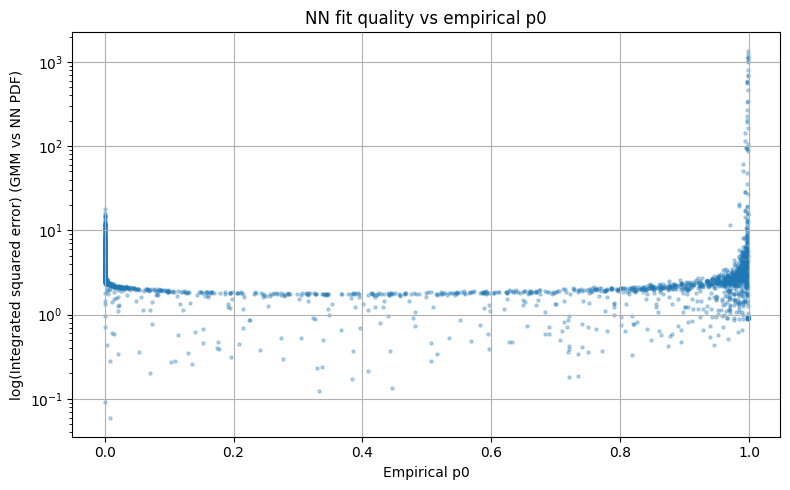

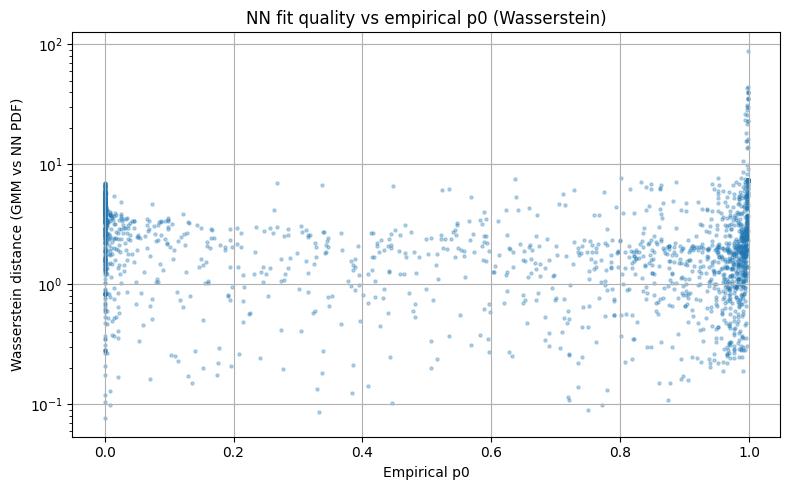

In [41]:

p0_vals = []
fit_errors = [] # ise
wd_errors = [] # wasserstein
fit_indices = []

for ind in valid_file_indices:
    if ind > 5000:
        break
    theta = np.array(all_thetas[ind])
    theta_norm = (theta - thetas_means) / thetas_stds
    p0_nn, w1_nn, mu1_nn, sigma1_nn, mu2_nn, sigma2_nn, logwd_nn = outputs_nn[ind]
    p0_gmm, w_gmm, mu_gmm, sigma_gmm, logwd_gmm = outputs_raw[ind]

    x = np.linspace(x_global_min, x_global_max, 500)
    dx = x[1] - x[0]

    gmm_pdf = sum(w * norm.pdf(x, loc=mu, scale=sigma)
                  for w, mu, sigma in zip(w_gmm, mu_gmm, sigma_gmm))
    nn_pdf = (w1_nn * norm.pdf(x, loc=mu1_nn, scale=abs(sigma1_nn)) +
              (1 - w1_nn) * norm.pdf(x, loc=mu2_nn, scale=abs(sigma2_nn)))

    ise = np.sum((gmm_pdf - nn_pdf) ** 2) * dx
    gmm_cdf = np.cumsum(gmm_pdf) * dx
    nn_cdf = np.cumsum(nn_pdf) * dx
    wd = np.sum(np.abs(gmm_cdf - nn_cdf)) * dx

    p0_vals.append(p0_gmm)
    fit_errors.append(ise)
    wd_errors.append(wd)
    fit_indices.append(ind)

p0_vals = np.array(p0_vals)
fit_errors = np.array(fit_errors)
wd_errors = np.array(wd_errors)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(p0_vals, fit_errors, alpha=0.3, s=5)
ax.set_xlabel("Empirical p0")
ax.set_ylabel("log(Integrated squared error) (GMM vs NN PDF)")
ax.set_title("NN fit quality vs empirical p0")
ax.set_yscale("log")
ax.grid(True)
plt.tight_layout()
plt.show()

fig2, ax2 = plt.subplots(figsize=(8, 5))
ax2.scatter(p0_vals, wd_errors, alpha=0.3, s=5)
ax2.set_xlabel("Empirical p0")
ax2.set_ylabel("Wasserstein distance (GMM vs NN PDF)")
ax2.set_title("NN fit quality vs empirical p0 (Wasserstein)")
ax2.set_yscale("log")
ax2.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# rows = [(ind, *vals) for ind, vals in high_p0_thetas.items()]
# pd.DataFrame(rows, columns=['file_idx', 'discspacing', 'length_ratio', 'b', 'p0_emp']).to_csv(
#     data_dir / 'get_more_data_for.csv', index=False)
# print(f'Saved {len(rows)} high-p0 thetas to get_more_data_for.csv')
# # Now, run MatLab code to compute more data.

In [ ]:
p0_zero_pos = np.where(np.array(p0_vals) == 0)[0]
worst_p0_zero = p0_zero_pos[np.argsort(np.array(fit_errors)[p0_zero_pos])[::-1]]
bad_fit_indices = [valid_file_indices[i] for i in worst_p0_zero[:30]]
from matplotlib.backends.backend_pdf import PdfPages

outputs_dir = data_dir.parent.parent / "outputs"
outputs_dir.mkdir(exist_ok=True)

with PdfPages(outputs_dir / "worst cases ise gmm_vs_nn (before additional trials).pdf") as pdf:
    for ind in bad_fit_indices:
        theta = np.array(all_thetas[ind])
        theta_norm = (theta - thetas_means) / thetas_stds
        p0_gmm, w_gmm, mu_gmm, sigma_gmm, logwd_gmm = outputs_raw[ind]
        p0_nn, w1_nn, mu1_nn, sigma1_nn, mu2_nn, sigma2_nn, logwd_nn = outputs_nn[ind]

        x = np.linspace(x_global_min, x_global_max, 200)

        gmm_pdf = sum(w * norm.pdf(x, loc=mu, scale=sigma)
                      for w, mu, sigma in zip(w_gmm, mu_gmm, sigma_gmm))
        nn_pdf = (w1_nn * norm.pdf(x, loc=mu1_nn, scale=abs(sigma1_nn)) +
                  (1 - w1_nn) * norm.pdf(x, loc=mu2_nn, scale=abs(sigma2_nn)))

        fig, ax = plt.subplots()
        ax.plot(x, gmm_pdf, color="blue", label="GMM fit")
        ax.plot(x, nn_pdf, color="red", label="NN")
        ax.set_title(f"file {ind} | GMM p0={p0_gmm:.4f} | NN p0={p0_nn:.3f} | GMM mu1={mu_gmm[0]:.2f} | NN mu1={mu1_nn:.2f}")
        ax.set_xlabel("log(Q)")
        ax.legend()
        pdf.savefig(fig)
        plt.close(fig)

print("Saved plots.")

In [ ]:
p0_zero_pos = np.where(np.array(p0_vals) == 0)[0]
worst_p0_zero_wd = p0_zero_pos[np.argsort(np.array(wd_errors)[p0_zero_pos])[::-1]]
bad_fit_indices_wd = [fit_indices[i] for i in worst_p0_zero_wd[:30]]
from matplotlib.backends.backend_pdf import PdfPages

outputs_dir = data_dir.parent.parent / "outputs"
outputs_dir.mkdir(exist_ok=True)

with PdfPages(outputs_dir / "worst cases wasserstein gmm_vs_nn (before additional trials).pdf") as pdf:
    for ind in bad_fit_indices_wd:
        theta = np.array(all_thetas[ind])
        theta_norm = (theta - thetas_means) / thetas_stds
        p0_gmm, w_gmm, mu_gmm, sigma_gmm, logwd_gmm = outputs_raw[ind]
        p0_nn, w1_nn, mu1_nn, sigma1_nn, mu2_nn, sigma2_nn, logwd_nn = outputs_nn[ind]

        x = np.linspace(x_global_min, x_global_max, 200)

        gmm_pdf = sum(w * norm.pdf(x, loc=mu, scale=sigma)
                      for w, mu, sigma in zip(w_gmm, mu_gmm, sigma_gmm))
        nn_pdf = (w1_nn * norm.pdf(x, loc=mu1_nn, scale=abs(sigma1_nn)) +
                  (1 - w1_nn) * norm.pdf(x, loc=mu2_nn, scale=abs(sigma2_nn)))

        fig, ax = plt.subplots()
        ax.plot(x, gmm_pdf, color="blue", label="GMM fit")
        ax.plot(x, nn_pdf, color="red", label="NN")
        ax.set_title(f"file {ind} | GMM p0={p0_gmm:.4f} | NN p0={p0_nn:.3f} | GMM mu1={mu_gmm[0]:.2f} | NN mu1={mu1_nn:.2f}")
        ax.set_xlabel("log(Q)")
        ax.legend()
        pdf.savefig(fig)
        plt.close(fig)

print("Saved plots.")